In [ ]:
import sys

sys.path.append("../src")

from data_processing.load import (
    load_weather_forecast,
    load_weather_nowcast,
    load_windpower,
    load_windparks,
    load_and_preprocess_data,
)
from data_processing.preprocess import (
    filter_bid_zone,
    align_windpower_and_weather,
    merge_metadata,
    multiindex,
    capacity_factor,
    split_train_test_meta,
)
from data_processing.features import winddir_transform, scale_features, get_input_shaped
from data_processing.utils import (
    load_checkpoint,
    save_checkpoint,
    run_inference_bnn,
    run_svi,
)
from models.model import (
    WindPowerModel,
    model,
    bnn_uninformed_embeddings,
    quantile_bnn_model,
)

import pandas as pd
import jax
import jax.numpy as jnp
import numpy as np
import torch
from torch import nn, optim
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from jax import random
import time
from numpyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
import arviz as az
import scipy
from scipy.stats import percentileofscore
from numpyro.infer.autoguide import AutoNormal
from numpyro.optim import Adam

In [ ]:
jax.config.update("jax_num_cpu_devices", 6)  # I have 8 physical cores

### Load data and preprocess

- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:

- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)


In [ ]:
# Load data
weather_forecast = load_weather_forecast("../data/met_forecast.parquet")
weather_nowcast = load_weather_nowcast("../data/met_nowcast.parquet")
windpower = load_windpower("../data/wind_power_per_bidzone.parquet")
windparks = load_windparks("../data/windparks_bidzone.csv")

# Apply wind direction transformation
# _winddir_transformed_forecast = winddir_transform(weather_forecast, prefix='wd10m_', n_members=15)
_winddir_transformed_nowcast = winddir_transform(
    weather_nowcast, columns=["wind_direction_10m"]
)
weather_nowcast = pd.concat([weather_nowcast, _winddir_transformed_nowcast], axis=1)

# Preprocessing pipeline
bid_zone = "ELSPOT NO1"
windparks_in_bid_zone = filter_bid_zone(windparks, bid_zone)
_windpower_in_bid_zone = windpower[bid_zone].dropna()

# Align windpower and weather, only keep timestamps which are present in both datasets
_weather_nowcast_in_bid_zone, _windpower_in_bid_zone = align_windpower_and_weather(
    _windpower_in_bid_zone, weather_nowcast
)

_weather_nowcast_in_bid_zone = merge_metadata(
    _weather_nowcast_in_bid_zone, windparks_in_bid_zone
)


# MultiIndex (time, windpark), operating_power_max is NaN for windparks not yet operational
weather_nowcast_in_bid_zone = multiindex(
    _weather_nowcast_in_bid_zone, windparks_in_bid_zone
)

# Capacity factor
windpower_in_bid_zone = capacity_factor(bid_zone, _windpower_in_bid_zone)

assert (_windpower_in_bid_zone.index == windpower_in_bid_zone.index).all()

# Only use timestamps where all wind parks are operational
# TODO find a better way how to deal with that
start_time = windparks_in_bid_zone["prod_start_new"].max()
windpower_in_bid_zone = windpower_in_bid_zone.loc[start_time:]
weather_nowcast_in_bid_zone = weather_nowcast_in_bid_zone.loc[start_time:]


# Split into train and test data
feature_cols = [
    "air_temperature_2m",
    "air_pressure_at_sea_level",
    "relative_humidity_2m",
    "wind_speed_10m",
    "wind_direction_10m_x",
    "wind_direction_10m_y",
]
site_meta_cols = ["operating_power_max", "windpark_id"]
scale_cols = [c for c in feature_cols if not c.startswith("wind_direction")]

split_time = pd.Timestamp("2025-01-01 00:00:00", tz="CET")

df_train_X, df_train_Y, df_test_X, df_test_Y, sites_meta_unscaled = (
    split_train_test_meta(
        weather_nowcast_in_bid_zone,
        windpower_in_bid_zone,
        feature_cols,
        site_meta_cols,
        split_time,
    )
)

# Scaling
df_train_X_scaled, df_test_X_scaled = scale_features(df_train_X, df_test_X, scale_cols)
mean_sites = sites_meta_unscaled.mean()
std_sites = sites_meta_unscaled.std()
sites_meta = ((sites_meta_unscaled - mean_sites) / std_sites)[:, None]

# Convert to numpy arrays
X_train = get_input_shaped(df_train_X_scaled, feature_cols)
X_test = get_input_shaped(df_test_X_scaled, feature_cols)

Y_train_cf = df_train_Y["capacity_factor"].to_numpy(jnp.float32)
Y_train_aval = df_train_Y["available_capacity"].to_numpy(jnp.float32)
Y_train_gen = df_train_Y["generation"].to_numpy(jnp.float32)

Y_test_cf = df_test_Y["capacity_factor"].to_numpy(jnp.float32)
Y_test_aval = df_test_Y["available_capacity"].to_numpy(jnp.float32)
Y_test_gen = df_test_Y["generation"].to_numpy(jnp.float32)


print("Preprocessing done. X_train shape:", X_train.shape)
print("Preprocessing done. X_test shape:", X_test.shape)

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


In [ ]:
assert (
    weather_nowcast_in_bid_zone.index.get_level_values("time").nunique()
    == windpower_in_bid_zone.index.nunique()
)
assert np.isclose(
    windpower_in_bid_zone["available_capacity"]
    * windpower_in_bid_zone["capacity_factor"],
    windpower_in_bid_zone["generation"],
).all()
assert df_train_X.index.get_level_values("time").unique().equals(df_train_Y.index)
assert df_test_X.index.get_level_values("time").unique().equals(df_test_Y.index)

### Classic NN

- shared weights for all parks
- wind park specific embeddings (max_operational_power as input) with embed_dim


In [5]:
X_train_tensor = torch.tensor(X_train)
Y_train_cf_tensor = torch.tensor(Y_train_cf)
Y_train_gen_tensor = torch.tensor(Y_train_gen)
X_test_tensor = torch.tensor(X_test)
Y_test_cf_tensor = torch.tensor(Y_test_cf)
sites_meta_tensor = torch.tensor(sites_meta, dtype=torch.float32)

In [6]:
windparks_in_bid_zone

,substation_name,operating_power_max,prod_start_new
0,Engerfjellet,52.8,2022-09-19 13:00:00
1,Hån Vindpark,21.0,2022-10-26 22:00:00
2,Kjølberget,55.9,2020-07-07 09:00:00
3,Marker Vindpark,54.0,2020-01-01 00:00:00
4,Raskiftet,111.6,2020-01-01 00:00:00
5,Songkjølen,110.4,2021-08-24 10:00:00


In [ ]:
nn_model = WindPowerModel(
    len(windparks_in_bid_zone), len(feature_cols), 3, sites_meta.shape[1]
)

optimizer = optim.Adam(nn_model.parameters(), lr=1e-3)
criterion = nn.MSELoss()


for step in range(3000):
    nn_model.train()
    optimizer.zero_grad()
    y_site_pred, y_sum_pred = nn_model(X_train_tensor, sites_meta_tensor)

    loss = criterion(y_sum_pred, Y_train_gen_tensor)

    loss.backward()
    optimizer.step()

    if step % 250 == 0:
        print(f"Step {step:3d} | Loss: {loss.item():.4f}")

Step   0 | Loss: 20476.5781
Step 250 | Loss: 7083.1499
Step 500 | Loss: 4522.9556
Step 750 | Loss: 3784.6152
Step 1000 | Loss: 3556.8079
Step 1250 | Loss: 3441.8865
Step 1500 | Loss: 3345.8162
Step 1750 | Loss: 3281.0649
Step 2000 | Loss: 3241.7979
Step 2250 | Loss: 3213.2546
Step 2500 | Loss: 3186.0750
Step 2750 | Loss: 3155.0139


In [ ]:
nn_model.eval()
with torch.no_grad():
    y_site_pred, y_sum_pred = nn_model(X_test_tensor, sites_meta_tensor)

# Rescale to generation prediction
Y_pred = y_sum_pred.numpy()  # * Y_test_aval
mse = mean_squared_error(Y_test_gen, Y_pred)
rmse = jnp.sqrt(mse)


print(f"Evaluation metrics:")
print(f"RMSE: {rmse:.2f} MW")

Evaluation metrics:
RMSE: 73.55 MW


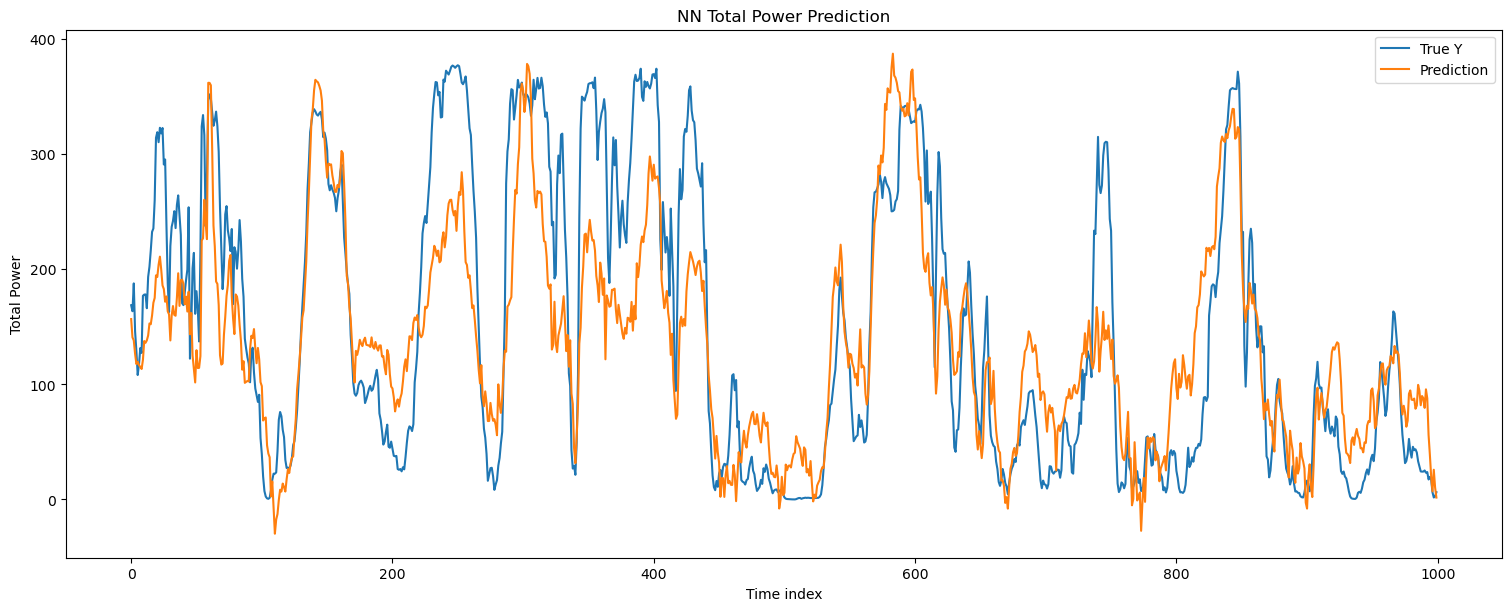

In [ ]:
# Plot
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_gen[:n_plot], label="True Y")
ax.plot(Y_pred[:n_plot], label="Prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="NN Total Power Prediction")
ax.legend()
plt.show()

### Simple BNN

input: (timestamps, wind parks, features)
output: (timestamps)


In [ ]:
D_H = 32
args = {
    "num_warmup": 10,
    "num_samples": 30,
    "num_chains": 6,
}

rng_key, rng_key_predict = random.split(random.PRNGKey(0))

Use MCMC


In [12]:
samples = run_inference_bnn(model, args, rng_key, X_train, Y_train_gen, D_H)

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     b1[0]      0.92      1.10      0.55     -0.17      2.94      5.02      2.34
     b1[1]      0.69      1.52      1.18     -1.83      2.93      3.25      4.94
     b1[2]     -0.99      1.85     -1.43     -3.99      1.78      3.84      2.87
     b1[3]     -0.95      1.47     -1.44     -2.41      2.18      4.61      1.86
     b1[4]      0.37      1.24      0.78     -1.55      1.85      3.35      4.43
     b1[5]      0.65      1.31      0.64     -1.41      2.60      4.13      2.36
     b1[6]      0.31      0.91      0.16     -0.62      1.82      3.57      2.99
     b1[7]      0.15      1.41      0.73     -2.07      1.74      3.94      3.54
     b1[8]      1.19      1.05      0.90     -0.44      2.79      3.88      2.60
     b1[9]     -0.20      2.10      0.14     -3.10      2.81      3.64      3.68
    b1[10]     -0.46      1.24     -0.32     -2.91      0.96      3.37      4.08
    b1[11]     -0.07      1

In [33]:
save_checkpoint(samples, "model", args, rng_key)

Saved checkpoint for model 'model': cf/model_2025-10-23_09-03-57_gen.pkl


'cf/model_2025-10-23_09-03-57_gen.pkl'

In [ ]:
# Posterior predictive
# vmap_args = (
#     samples,
#     random.split(rng_key_predict, args['num_samples'] * args['num_chains']),
# )
# preds = jax.vmap(lambda samples, rng_key: predict_bnn(model, rng_key, samples, X_test, D_H))(*vmap_args)

preds = Predictive(model, samples)(rng_key_predict, X_test)

Use Variational Inference


In [ ]:
guide = AutoNormal(model)
svi_result = run_svi(model, guide, rng_key, X_train, Y_train_gen)
params = svi_result.params
preds = Predictive(model, guide=guide, params=params, num_samples=500)(
    rng_key_predict, X_test
)

Final ELBO loss: 2241990.250


In [ ]:
preds_gen = preds["Y"]

preds_mean = preds_gen.mean(axis=0)
percentiles = np.percentile(preds_gen, [5, 95], axis=0)
median = np.percentile(preds_gen, 50, axis=0)

In [42]:
rmse = jnp.sqrt(jnp.mean((preds_mean - Y_test_gen) ** 2))
print("Test RMSE:", rmse)

Test RMSE: 106.23063


### Quantile Regression BNN


In [ ]:
# MCMC
samples = run_inference_bnn(
    quantile_bnn_model, args, rng_key, X_train, Y_train_gen, D_H
)
preds = Predictive(quantile_bnn_model, samples)(rng_key_predict, X_test)

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

In [ ]:
preds["Y_q0.05"], preds["Y_q0.50"], preds["Y_q0.95"]

In [ ]:
guide_quantile = AutoNormal(quantile_bnn_model)
svi_result_quantile = run_svi(
    quantile_bnn_model, guide_quantile, rng_key, X_train, Y_train_gen
)
losses_quantile = svi_result_quantile.losses
print(f"Final ELBO loss: {losses_quantile[-1]:.3f}")


params_quantile = svi_result_quantile.params
predictive = Predictive(
    quantile_bnn_model, guide=guide_quantile, params=params_quantile, num_samples=500
)(rng_key_predict, X_test)

### Plots

- VI loss
- Model rendering
- Residuals
- Forecast with percentiles
- std noise
- PIT histogram


Final ELBO loss: 2241990.250


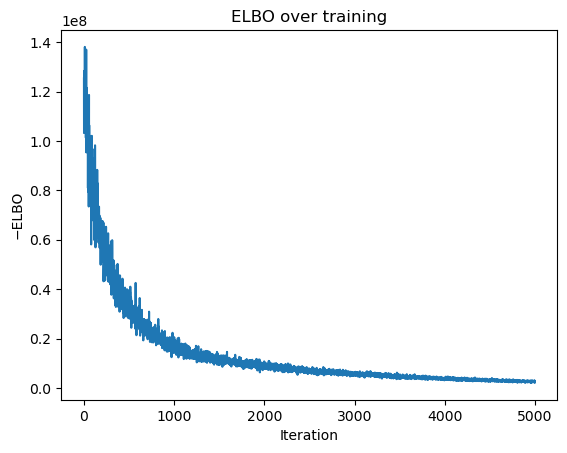

In [ ]:
losses = svi_result.losses
print(f"Final ELBO loss: {losses[-1]:.3f}")
plt.plot(losses)
plt.title("ELBO over training")
plt.xlabel("Iteration")
plt.ylabel("−ELBO")
plt.show()

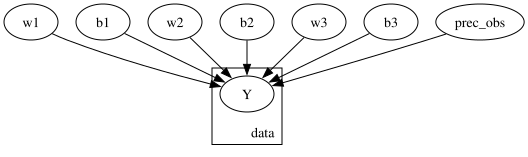

In [ ]:
import numpyro

numpyro.render_model(
    model,
    model_args=(X_test,),
)

skew: 0.30540776


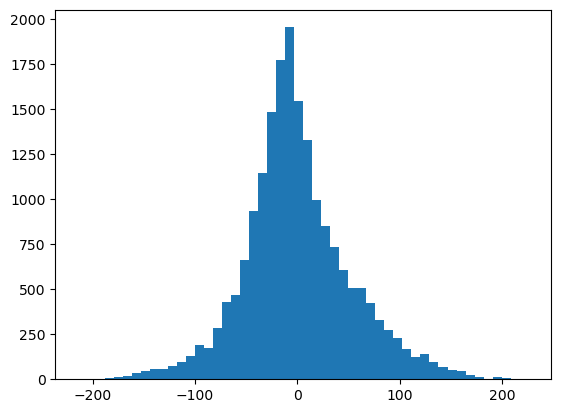

In [ ]:
# positive residuals correspond to missed peaks
# positive tail: in general more underpredictions (train data)
pred_train_mcmc = Predictive(model, samples)(rng_key_predict, X_train)["Y"]
pred_train_vi = Predictive(model, guide=guide, params=params, num_samples=500)(
    rng_key_predict, X_train
)["Y"]

yhat = jnp.mean(pred_train_vi, axis=0)
resid = Y_train_gen - yhat
print("skew:", scipy.stats.skew(np.array(resid)))
plt.hist(np.array(resid), bins=50)
plt.show()

In [ ]:
# make it wrong: assume posterior is normal distributed
normal_mean = preds_gen.mean(axis=0)
normal_std = preds_gen.std(axis=0)
normal_lower = normal_mean - 1.96 * normal_std
normal_upper = normal_mean + 1.96 * normal_std


# HDI (high densitiy interval)
hdi = az.hdi(np.expand_dims(preds_gen, axis=0), hdi_prob=0.90)

# Percentiles
percentiles = np.percentile(preds_gen, [5, 95], axis=0)
median = np.percentile(preds_gen, 50, axis=0)

# Widths of different intervals (90% CI)
hdi_avg_width = (hdi[:, 1] - hdi[:, 0]).mean()
percentile_avg_width = (percentiles[1] - percentiles[0]).mean()
normal_ci_avg_width = (normal_upper - normal_lower).mean()

In [ ]:
hdi_lower, hdi_upper = hdi[:, 0], hdi[:, 1]
inside = np.logical_and(Y_test_gen >= hdi_lower, Y_test_gen <= hdi_upper)
coverage = inside.mean()
print(f"Empirical coverage (0.05-0.95): {coverage:.2%}")

Empirical coverage: 70.99%


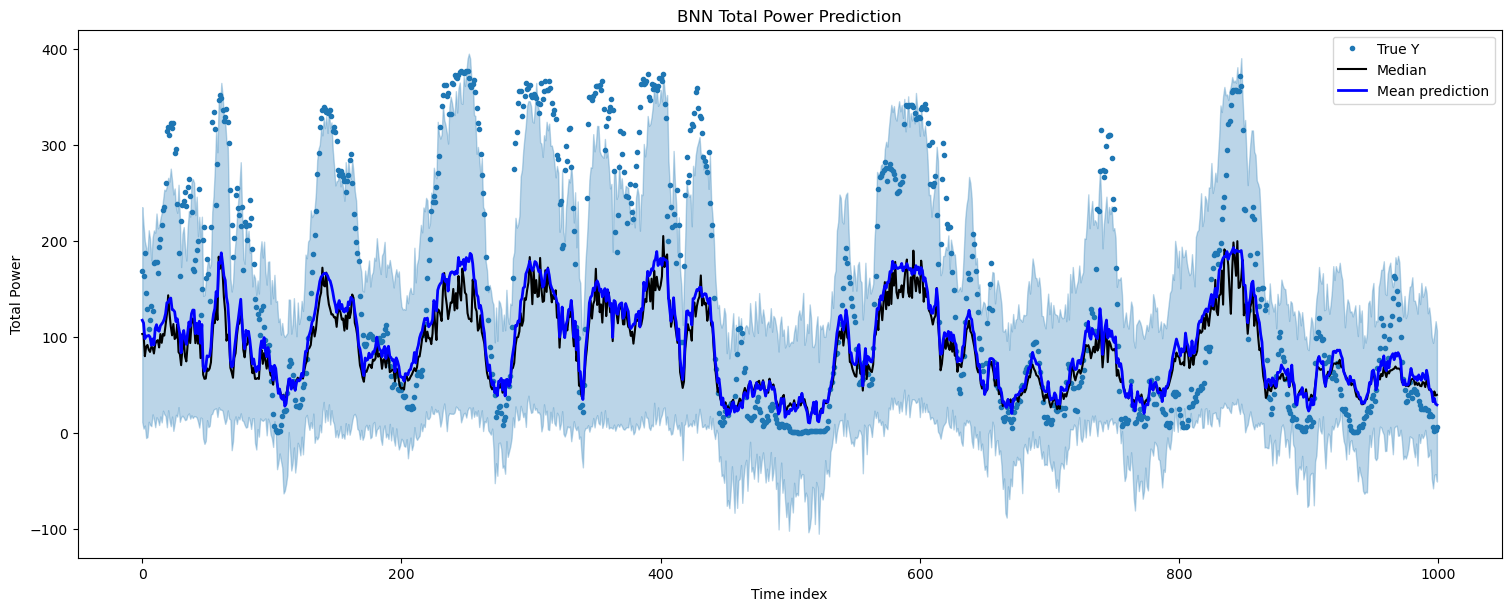

In [ ]:
# Plot 90% CI
n_plot = 1000
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(Y_test_gen[:n_plot], ".", label="True Y")
ax.plot(median[:n_plot], label="Median", color="black")
# ax.fill_between(np.arange(n_plot), _lower[:n_plot], _upper[:n_plot], color="green", alpha=0.5)
ax.fill_between(
    np.arange(n_plot), hdi[:n_plot, 0], hdi[:n_plot, 1], color="C0", alpha=0.3
)
# ax.fill_between(np.arange(n_plot), percentiles[0, :n_plot], percentiles[1, :n_plot], color="lightblue", alpha=0.7)

ax.plot(preds_mean[:n_plot], "b", lw=2, label="Mean prediction")
ax.set(xlabel="Time index", ylabel="Total Power", title="BNN Total Power Prediction")
ax.legend()
plt.show()

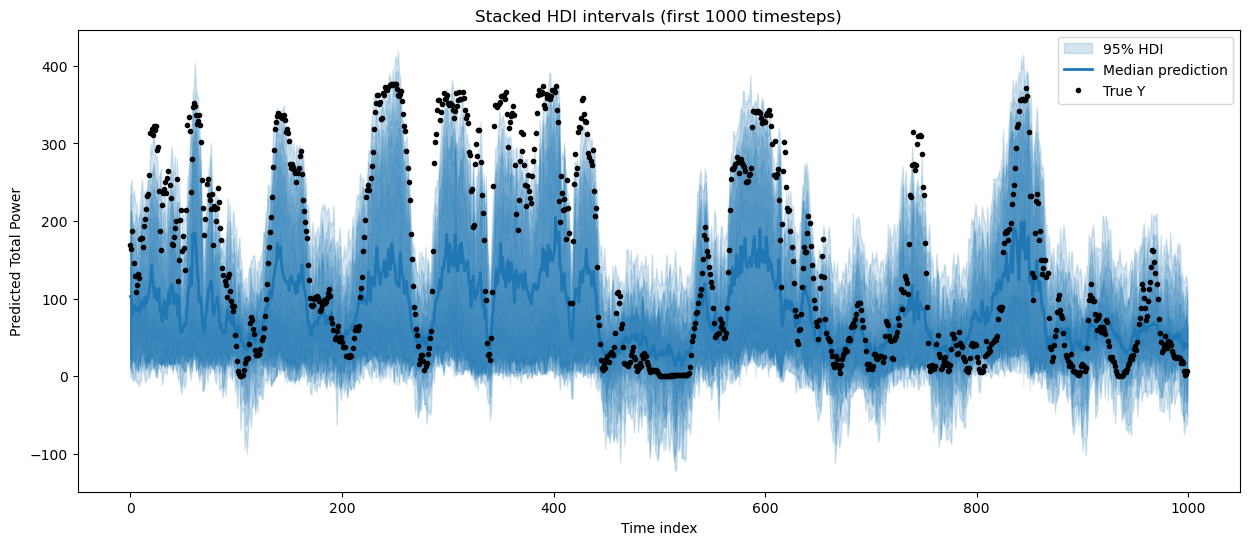

In [ ]:
# Only plot first n_plot timesteps
n_plot = 1000

# Compute multiple HDI levels
hdi_probs = np.arange(0.05, 1.0, 0.05)
preds_hdi = np.expand_dims(preds_gen, axis=0)
hdis = {float(p): az.hdi(preds_hdi, hdi_prob=float(p)) for p in hdi_probs}

X_new = np.arange(n_plot)
median = np.percentile(preds_gen, 50, axis=0)

plt.figure(figsize=(15, 6))
max_p = max(hdis.keys())
for p in hdi_probs:
    hdi = hdis[p][:n_plot]
    alpha = 0.2 * float(p)
    label = f"{int(p*100)}% HDI" if p == max_p else None
    plt.fill_between(X_new, hdi[:, 0], hdi[:, 1], color="C0", alpha=alpha, label=label)

plt.plot(X_new, median[:n_plot], color="C0", lw=2, label="Median prediction")
plt.plot(Y_test_gen[:n_plot], ".", color="black", label="True Y")
plt.title("Stacked HDI intervals (first {} timesteps)".format(n_plot))
plt.xlabel("Time index")
plt.ylabel("Predicted Total Power")
plt.legend()
plt.show()

<Axes: title={'center': 'std noise'}>

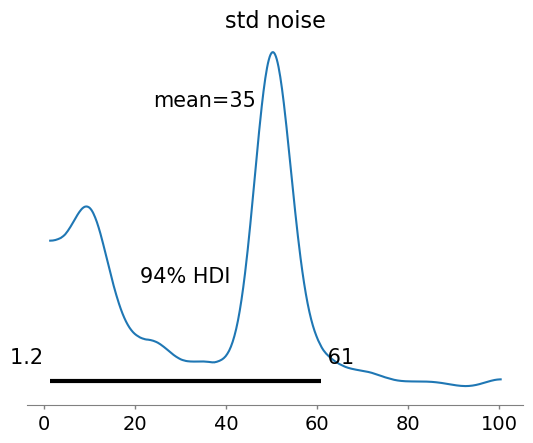

In [ ]:
# Plot std noise
az.plot_posterior({"std noise": 1.0 / jnp.sqrt(samples["prec_obs"])})

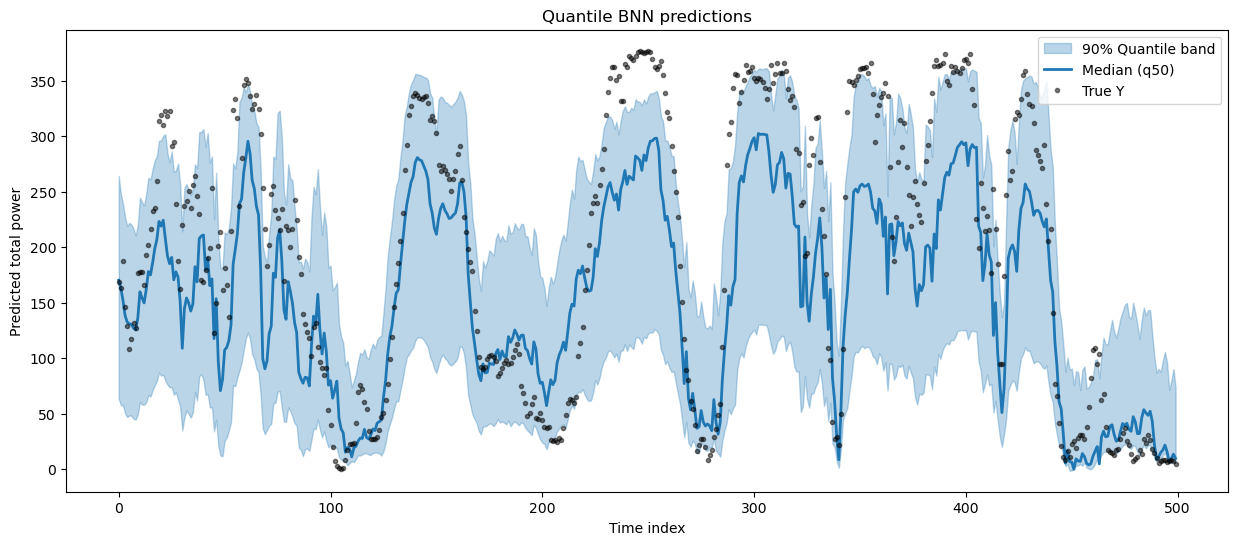

In [ ]:
q05 = preds["Y_q0.05"].mean(axis=0)
q50 = preds["Y_q0.50"].mean(axis=0)
q95 = preds["Y_q0.95"].mean(axis=0)
import matplotlib.pyplot as plt
import numpy as np

n_plot = 500  # nur erste 500 Zeitpunkte zum Anschauen
X_new = np.arange(n_plot)

plt.figure(figsize=(15, 6))

# Unsicherheitsband (z. B. 90%)
plt.fill_between(
    X_new, q05[:n_plot], q95[:n_plot], color="C0", alpha=0.3, label="90% Quantile band"
)

# Median (0.5)
plt.plot(X_new, q50[:n_plot], color="C0", lw=2, label="Median (q50)")

# True Y
plt.plot(Y_test_gen[:n_plot], ".", color="black", label="True Y")

plt.title("Quantile BNN predictions")
plt.xlabel("Time index")
plt.ylabel("Predicted total power")
plt.legend()
plt.show()

In [ ]:
inside = (Y_test_gen >= q05) & (Y_test_gen <= q95)
coverage_90 = inside.mean()
print(f"Empirical coverage (0.05–0.95): {coverage_90:.3f}")

below_median = (Y_test_gen <= q50).mean()
print(f"Below median (should be ~0.5): {below_median:.3f}")

Empirische Abdeckung (0.05–0.95): 0.741


PIT mean: 0.6710383567278524 (should be uniform if calibrated)


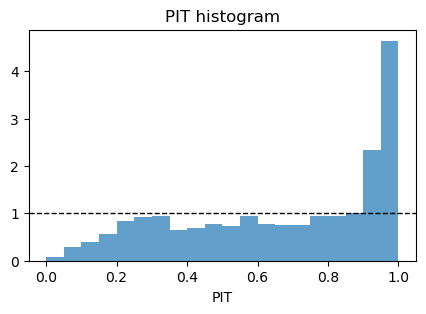

In [ ]:
pits = np.array(
    [
        percentileofscore(preds_gen[:, t], Y_test_gen[t], kind="mean") / 100.0
        for t in range(preds_gen.shape[1])
    ]
)
pits_mean = pits.mean()
print(f"PIT mean: {pits_mean} (should be uniform if calibrated)")

plt.figure(figsize=(5, 3))
plt.hist(pits, bins=20, range=(0, 1), density=True, alpha=0.7)
plt.axhline(1.0, color="k", ls="--", lw=1)  # reference
plt.xlabel("PIT")
plt.title("PIT histogram")
plt.show()